# GemmaForge probe evaluation report

Adapted from the hallucination-probes paper methodology (Obeso et al. 2025,
arxiv.org/abs/2509.03531). For each of five leakage-aware splits, this
notebook fits a fresh linear probe on the training partition, scores the
test partition, and reports AUC (with bootstrap CI), F1, recall at
5%/10% FPR, calibration (Brier + ECE), and three baselines
(random / length / regex).

**What to look at first**: the `heldout_lang::test=javascript` and
`heldout_lang::test=python` rows in the headline table. Those are the
strictest credible stress tests — the probe never sees the target
language at fit time. Everything else is easier.

## Setup

In [1]:
import sys
from pathlib import Path

# Repo root for imports when running from `notebooks/`.
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "src" / "eval").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import matplotlib.pyplot as plt

from src.eval import probe_io, protocol, baselines as bl_mod, report as report_mod
from src.eval.metrics import compute_clf_metrics, bootstrap_auc_ci

## Configuration

Layer 17 is the current shipping probe layer. Swap `LAYER` to 8 / 26 / 34
to re-run on the other captured layers.

In [2]:
LAYER = 17
ACTIVATIONS = ROOT / f"data/activations_v2/activations_layer{LAYER:02d}.npz"
PAIRS = ROOT / "data/pairs.jsonl"

print(f"layer = {LAYER}")
print(f"activations = {ACTIVATIONS}")
print(f"pairs = {PAIRS}")

layer = 17
activations = /Users/mmtf/p/tmp/2026-05-18-peaktwilight-gemmaforge/data/activations_v2/activations_layer17.npz
pairs = /Users/mmtf/p/tmp/2026-05-18-peaktwilight-gemmaforge/data/pairs.jsonl


## Load data

In [3]:
X, y = probe_io.load_activations(ACTIVATIONS)
rows = probe_io.load_pairs(PAIRS)
assert len(rows) == len(y), f"row count mismatch: pairs={len(rows)} npz={len(y)}"
print(f"X.shape = {X.shape}")
print(f"y_pos   = {int(y.sum())} / {len(y)}  ({y.mean():.3f})")
print(f"langs   = {sorted(set(r.get('lang') for r in rows))}")
print(f"sources = {sorted(set(r.get('source') for r in rows))}")

X.shape = (1198, 1536)
y_pos   = 599 / 1198  (0.500)
langs   = ['javascript', 'python']
sources = ['CyberSecEval', 'CyberSecEval-leadup']


## Run the full split bundle

Each split refits the probe on its own training partition, so every row
in the table is an honest OOD number for *that* axis.

In [4]:
full = protocol.full_report(
    X, y, rows,
    activations_path=str(ACTIVATIONS.relative_to(ROOT)),
    pairs_path=str(PAIRS.relative_to(ROOT)),
    layer=LAYER,
    refit=True,
    baselines=bl_mod.all_baselines(),
)
print(report_mod.render_markdown(full))

# Probe evaluation report

Activations: `data/activations_v2/activations_layer17.npz` (layer 17, N=1198, pos=599)
Pairs metadata: `data/pairs.jsonl`
Probe fit mode: `refit per split (OOD)`

## Per-split metrics

| split | AUC (95% CI) | F1 | R@5%FPR | R@10%FPR | Brier | ECE | n_test | pos |
|---|---|---|---|---|---|---|---|---|
| `random_stratified` | 0.963 (0.941-0.983) | 0.921 | 0.833 | 0.942 | 0.071 | 0.065 | 240 | 120 |
| `group_repo` | 0.958 (0.930-0.980) | 0.924 | 0.790 | 0.924 | 0.075 | 0.082 | 238 | 119 |
| `heldout_cwe::CWE-78` | 0.923 (0.881-0.960) | 0.857 | 0.561 | 0.793 | 0.125 | 0.139 | 165 | 82 |
| `heldout_cwe::CWE-338` | 0.923 (0.876-0.962) | 0.809 | 0.658 | 0.785 | 0.134 | 0.137 | 158 | 79 |
| `heldout_cwe::CWE-95` | 0.942 (0.903-0.973) | 0.890 | 0.782 | 0.897 | 0.096 | 0.089 | 159 | 78 |
| `heldout_cwe::CWE-94` | 0.960 (0.926-0.986) | 0.908 | 0.846 | 0.908 | 0.077 | 0.073 | 130 | 65 |
| `heldout_cwe::CWE-328` | 0.944 (0.904-0.976) | 0.822 | 0.600 | 0.745 | 0.120 | 0.1

## ROC curves per split

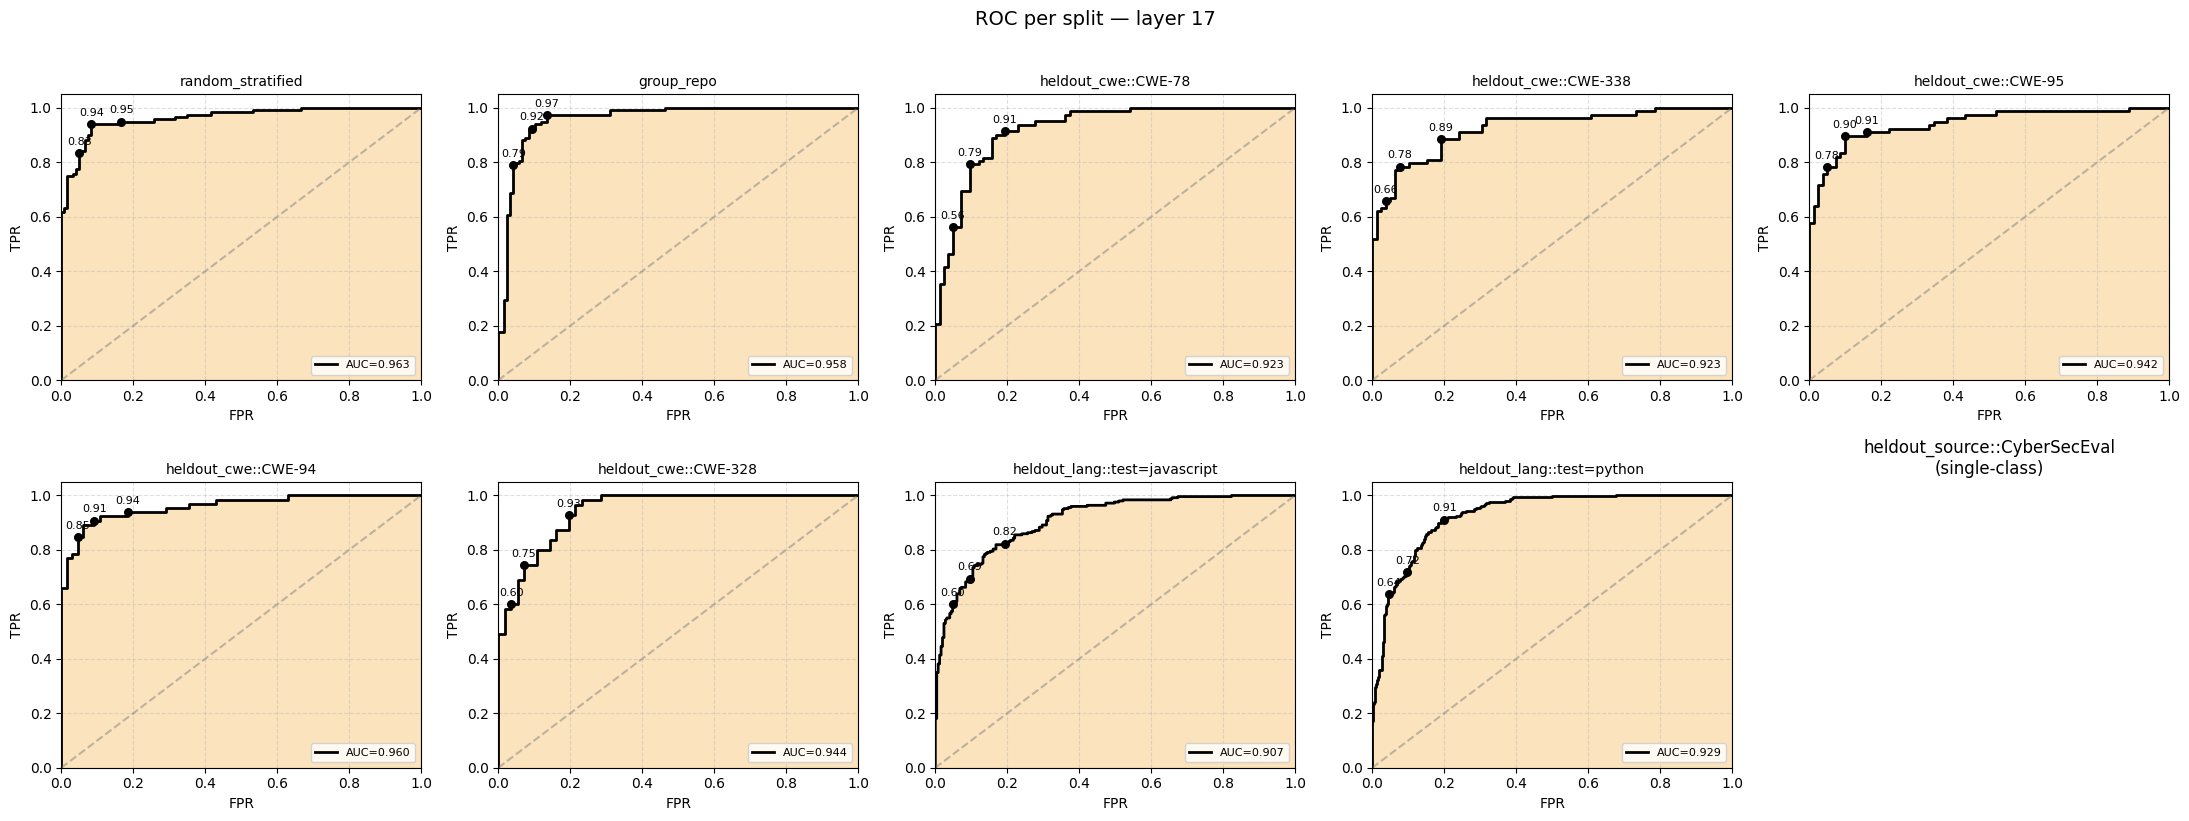

In [5]:
from sklearn.metrics import roc_curve
from src.eval.splits import make_splits
from src.eval.probe_io import fit_logreg_on_split

splits = make_splits(rows, y)
fig, axes = plt.subplots(2, 5, figsize=(22, 8), squeeze=False)
for ax, sp in zip(axes.flat, splits):
    tr, te = sp.train_idx, sp.test_idx
    if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2:
        ax.set_title(f"{sp.name}\n(single-class)")
        ax.axis("off")
        continue
    probe = fit_logreg_on_split(X, y, tr)
    probs = probe.score(X[te])
    fpr, tpr, _ = roc_curve(y[te], probs)
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(y[te], probs)
    ax.plot(fpr, tpr, color="black", lw=2, label=f"AUC={auc:.3f}")
    ax.fill_between(fpr, tpr, color="#f9c97d", alpha=0.5)
    ax.plot([0, 1], [0, 1], "--", color="gray", alpha=0.5)
    for target in (0.05, 0.10, 0.20):
        idx = np.where(fpr <= target)[0]
        if len(idx):
            ax.scatter(fpr[idx[-1]], tpr[idx[-1]], color="black", s=30, zorder=5)
            ax.annotate(f"{tpr[idx[-1]]:.2f}", (fpr[idx[-1]], tpr[idx[-1]] + 0.03), fontsize=8, ha="center")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
    ax.set_title(sp.name, fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.4)
# Hide any unused axes.
for ax in axes.flat[len(splits):]:
    ax.axis("off")
plt.suptitle(f"ROC per split — layer {LAYER}", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Per-layer comparison

Cross-check that layer 17 is still the best layer under the worst credible
split (heldout_lang::javascript). If a different layer wins on the OOD
split, the shipping probe layer should change.

In [6]:
layer_aucs = {}
for layer_path in sorted((ROOT / "data/activations_v2").glob("activations_layer*.npz")):
    layer = int(layer_path.stem.split("layer")[-1])
    Xl, yl = probe_io.load_activations(layer_path)
    layer_aucs[layer] = {}
    for sp in splits:
        if len(np.unique(yl[sp.train_idx])) < 2 or len(np.unique(yl[sp.test_idx])) < 2:
            layer_aucs[layer][sp.name] = float("nan")
            continue
        pr = fit_logreg_on_split(Xl, yl, sp.train_idx)
        probs = pr.score(Xl[sp.test_idx])
        from sklearn.metrics import roc_auc_score
        layer_aucs[layer][sp.name] = float(roc_auc_score(yl[sp.test_idx], probs))

# Wide table.
split_names = list(next(iter(layer_aucs.values())).keys())
print(f"{'layer':>6s} | " + " | ".join(f"{n[:24]:>24s}" for n in split_names))
print("-" * (8 + (27 * len(split_names))))
for layer, aucs in sorted(layer_aucs.items()):
    cells = []
    for n in split_names:
        v = aucs[n]
        cells.append("    n/a" if np.isnan(v) else f"  {v:.3f}")
    print(f"{layer:>6d} | " + " | ".join(f"{c:>24s}" for c in cells))

 layer |        random_stratified |               group_repo |      heldout_cwe::CWE-78 |     heldout_cwe::CWE-338 |      heldout_cwe::CWE-95 |      heldout_cwe::CWE-94 |     heldout_cwe::CWE-328 | heldout_lang::test=javas | heldout_lang::test=pytho | heldout_source::CyberSec | heldout_source::CyberSec
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
     8 |                    0.927 |                    0.956 |                    0.904 |                    0.871 |                    0.900 |                    0.939 |                    0.921 |                    0.884 |                    0.890 |                      n/a |                      n/a
    17 |                    0.963 |                    0.958 |                    0.92

## Headline plot — leaky vs honest AUC

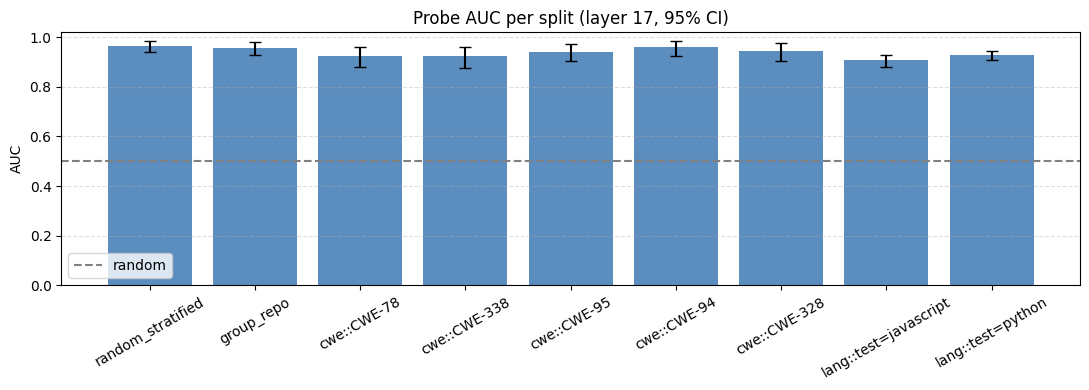

In [7]:
labels_x = []
values = []
errs_lo = []
errs_hi = []
for sp_report in full.splits:
    if np.isnan(sp_report.auc):
        continue
    labels_x.append(sp_report.split_name.replace("heldout_", ""))
    values.append(sp_report.auc)
    errs_lo.append(sp_report.auc - sp_report.auc_ci_lo)
    errs_hi.append(sp_report.auc_ci_hi - sp_report.auc)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(labels_x, values, color="#5b8dbe", yerr=[errs_lo, errs_hi], capsize=4)
ax.axhline(0.5, color="gray", linestyle="--", label="random")
ax.set_ylim(0, 1.02)
ax.set_ylabel("AUC")
ax.set_title(f"Probe AUC per split (layer {LAYER}, 95% CI)")
ax.tick_params(axis="x", rotation=30)
ax.legend()
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Save report bundle

Writes Markdown + JSON to `data/eval/`, same convention as
`scripts/eval_splits.py` but with the richer columns.

In [8]:
out_md = ROOT / "data/eval/report.md"
out_json = ROOT / "data/eval/report.json"
report_mod.write_report(full, out_md, out_json)
print(f"wrote {out_md}")
print(f"wrote {out_json}")

wrote /Users/mmtf/p/tmp/2026-05-18-peaktwilight-gemmaforge/data/eval/report.md
wrote /Users/mmtf/p/tmp/2026-05-18-peaktwilight-gemmaforge/data/eval/report.json
